In [ ]:
import os
import time
import random
import json
import copy
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms
from sklearn.metrics import f1_score, accuracy_score

# Fungsi untuk menetapkan Reproducibility (Seed Tetap)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan perangkat komputasi: {device}")

Menggunakan perangkat komputasi: cuda


In [ ]:
# 1. Definisi Transformasi Data (Dengan dan Tanpa Augmentasi untuk Uji Kontrol B4)
weights_ref = models.ResNet18_Weights.IMAGENET1K_V1
img_size = 224

# Pipeline dengan Augmentasi (Digunakan untuk B1, B2, B3, dan Skenario 2 B4)
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(img_size, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights_ref.transforms().mean, std=weights_ref.transforms().std),
])

# Pipeline tanpa Augmentasi (Digunakan untuk Skenario 1 Uji Kontrol B4)
eval_transforms = weights_ref.transforms()

# 2. Unduh Dataset Oxford-IIIT Pet
full_dataset_train = datasets.OxfordIIITPet(root="./data", split="trainval", download=True, transform=eval_transforms)
full_dataset_test = datasets.OxfordIIITPet(root="./data", split="test", download=True, transform=eval_transforms)

# 3. Filter Subset 10 Kelas Pertama (5 Ras Kucing & 5 Ras Anjing)
def filter_10_classes(dataset):
    indices = []
    for idx, (_, label) in enumerate(dataset):
        if label < 10:
            indices.append(idx)
    return indices

train_indices = filter_10_classes(full_dataset_train)
test_indices = filter_10_classes(full_dataset_test)

subset_trainval = Subset(full_dataset_train, train_indices)
subset_test = Subset(full_dataset_test, test_indices)

# 4. Pembagian Data Internal: 70% Train, 15% Validation, 15% Test (dari trainval)
val_size = int(0.15 * len(subset_trainval))
train_size = len(subset_trainval) - val_size

# Set transform spesifik untuk train subset
full_dataset_train_aug = datasets.OxfordIIITPet(root="./data", split="trainval", download=False, transform=train_transforms)
subset_trainval_aug = Subset(full_dataset_train_aug, train_indices)

# Split berbasis indeks yang konsisten
train_subset, val_subset = random_split(
    subset_trainval_aug,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Untuk test set
test_loader = DataLoader(subset_test, batch_size=32, shuffle=False, num_workers=2)
val_loader = DataLoader(Subset(full_dataset_train, [train_indices[i] for i in val_subset.indices]), batch_size=32, shuffle=False, num_workers=2)
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)

print(f"Jumlah data Latih (Train): {len(train_subset)}")
print(f"Jumlah data Validasi (Val): {len(val_subset)}")
print(f"Jumlah data Uji (Test): {len(subset_test)}")

Jumlah data Latih (Train): 847
Jumlah data Validasi (Val): 149
Jumlah data Uji (Test): 985


In [ ]:
def train_and_evaluate(model, model_name, optimizer, criterion, num_epochs=20, patience=4):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float('inf')
    patience_counter = 0

    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": []}
    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)

        epoch_train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = accuracy_score(all_labels, all_preds)

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

        # Early Stopping Logic
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping dipicu pada epoch {epoch+1}")
                break

    total_duration = time.time() - start_time
    model.load_state_dict(best_model_wts)

    # Evaluasi Akhir pada Test Set
    model.eval()
    test_preds, test_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            test_preds.extend(preds.cpu().numpy())
            test_labels.extend(labels.cpu().numpy())

    final_test_acc = accuracy_score(test_labels, test_preds)
    macro_f1 = f1_score(test_labels, test_preds, average='macro')

    metrics_summary = {
        "model_name": model_name,
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "total_params": sum(p.numel() for p in model.parameters()),
        "converged_epochs": len(history["epoch"]),
        "duration_seconds": round(total_duration, 2),
        "final_val_acc": round(float(epoch_val_acc), 4),
        "test_acc": round(float(final_test_acc), 4),
        "macro_f1": round(float(macro_f1), 4)
    }

    return model, history, metrics_summary

In [ ]:
print("--- MENJALANKAN KONDISI B1: Baseline from Scratch ---")
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

optimizer_b1 = optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
criterion = nn.CrossEntropyLoss()

model_b1, history_b1, metrics_b1 = train_and_evaluate(
    model_b1, "B1_FromScratch", optimizer_b1, criterion, num_epochs=20, patience=4
)
print("Metrik B1:", metrics_b1)

--- MENJALANKAN KONDISI B1: Baseline from Scratch ---
Epoch 1/20 | Train Loss: 2.4655 | Val Loss: 4.4958 | Val Acc: 0.1275
Epoch 2/20 | Train Loss: 2.1556 | Val Loss: 2.3361 | Val Acc: 0.2416
Epoch 3/20 | Train Loss: 2.0471 | Val Loss: 1.9134 | Val Acc: 0.3221
Epoch 4/20 | Train Loss: 1.9513 | Val Loss: 2.0440 | Val Acc: 0.2752
Epoch 5/20 | Train Loss: 1.9207 | Val Loss: 1.7548 | Val Acc: 0.3960
Epoch 6/20 | Train Loss: 1.8294 | Val Loss: 2.5014 | Val Acc: 0.1946
Epoch 7/20 | Train Loss: 1.8009 | Val Loss: 1.9873 | Val Acc: 0.3356
Epoch 8/20 | Train Loss: 1.7714 | Val Loss: 1.9672 | Val Acc: 0.3423
Epoch 9/20 | Train Loss: 1.7078 | Val Loss: 2.0149 | Val Acc: 0.3423
Early stopping dipicu pada epoch 9
Metrik B1: {'model_name': 'B1_FromScratch', 'trainable_params': 11181642, 'total_params': 11181642, 'converged_epochs': 9, 'duration_seconds': 101.3, 'final_val_acc': 0.3423, 'test_acc': 0.3706, 'macro_f1': 0.3356}


In [ ]:
print("--- MENJALANKAN KONDISI B2: Feature Extraction ---")
weights_b2 = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights_b2)

# Bekukan seluruh lapisan backbone
for param in model_b2.parameters():
    param.requires_grad = False

# Ganti layer classifier untuk 10 kelas
num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)
model_b2 = model_b2.to(device)

# Verifikasi parameter aktif (seharusnya 5.130 parameter untuk layer fc)
trainable_params = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)
print(f"Trainable Parameters B2: {trainable_params:,}")

optimizer_b2 = optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)
criterion = nn.CrossEntropyLoss()

model_b2, history_b2, metrics_b2 = train_and_evaluate(
    model_b2, "B2_FeatureExtraction", optimizer_b2, criterion, num_epochs=20, patience=4
)
print("Metrik B2:", metrics_b2)

--- MENJALANKAN KONDISI B2: Feature Extraction ---
Trainable Parameters B2: 5,130
Epoch 1/20 | Train Loss: 1.7939 | Val Loss: 1.1052 | Val Acc: 0.7651
Epoch 2/20 | Train Loss: 1.0382 | Val Loss: 0.6915 | Val Acc: 0.8859
Epoch 3/20 | Train Loss: 0.7596 | Val Loss: 0.4830 | Val Acc: 0.9060
Epoch 4/20 | Train Loss: 0.6162 | Val Loss: 0.3908 | Val Acc: 0.9329
Epoch 5/20 | Train Loss: 0.5462 | Val Loss: 0.3316 | Val Acc: 0.9262
Epoch 6/20 | Train Loss: 0.4760 | Val Loss: 0.3106 | Val Acc: 0.9128
Epoch 7/20 | Train Loss: 0.4365 | Val Loss: 0.2900 | Val Acc: 0.9262
Epoch 8/20 | Train Loss: 0.3951 | Val Loss: 0.2806 | Val Acc: 0.9195
Epoch 9/20 | Train Loss: 0.3632 | Val Loss: 0.2518 | Val Acc: 0.9195
Epoch 10/20 | Train Loss: 0.3426 | Val Loss: 0.2431 | Val Acc: 0.9195
Epoch 11/20 | Train Loss: 0.3460 | Val Loss: 0.2400 | Val Acc: 0.9128
Epoch 12/20 | Train Loss: 0.3203 | Val Loss: 0.2269 | Val Acc: 0.9262
Epoch 13/20 | Train Loss: 0.3058 | Val Loss: 0.2140 | Val Acc: 0.9329
Epoch 14/20 | Tra

In [ ]:
print("--- MENJALANKAN KONDISI B3: Progressive Fine-Tuning ---")
model_b3 = models.resnet18(weights=weights_b2)

# Bekukan awal, lalu buka layer4 dan fc
for param in model_b3.parameters():
    param.requires_grad = False

for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3 = model_b3.to(device)

# Differential Learning Rate
optimizer_b3 = optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

criterion = nn.CrossEntropyLoss()

model_b3, history_b3, metrics_b3 = train_and_evaluate(
    model_b3, "B3_FineTuning", optimizer_b3, criterion, num_epochs=20, patience=4
)
print("Metrik B3:", metrics_b3)

--- MENJALANKAN KONDISI B3: Progressive Fine-Tuning ---
Epoch 1/20 | Train Loss: 1.1274 | Val Loss: 0.2774 | Val Acc: 0.9530
Epoch 2/20 | Train Loss: 0.3076 | Val Loss: 0.1835 | Val Acc: 0.9597
Epoch 3/20 | Train Loss: 0.1860 | Val Loss: 0.1982 | Val Acc: 0.9195
Epoch 4/20 | Train Loss: 0.1187 | Val Loss: 0.1651 | Val Acc: 0.9530
Epoch 5/20 | Train Loss: 0.1121 | Val Loss: 0.1916 | Val Acc: 0.9262
Epoch 6/20 | Train Loss: 0.0652 | Val Loss: 0.1418 | Val Acc: 0.9597
Epoch 7/20 | Train Loss: 0.0419 | Val Loss: 0.1502 | Val Acc: 0.9597
Epoch 8/20 | Train Loss: 0.0470 | Val Loss: 0.1776 | Val Acc: 0.9530
Epoch 9/20 | Train Loss: 0.0403 | Val Loss: 0.1672 | Val Acc: 0.9262
Epoch 10/20 | Train Loss: 0.0296 | Val Loss: 0.1568 | Val Acc: 0.9463
Early stopping dipicu pada epoch 10
Metrik B3: {'model_name': 'B3_FineTuning', 'trainable_params': 8398858, 'total_params': 11181642, 'converged_epochs': 10, 'duration_seconds': 105.75, 'final_val_acc': 0.9463, 'test_acc': 0.8924, 'macro_f1': 0.8916}


In [ ]:
print("--- MENJALANKAN KONDISI B4: Uji Kontrol Data Augmentation ---")

# Skenario 4.1: Tanpa Augmentasi (Hanya Resize dan Normalisasi standar)
train_loader_no_aug = DataLoader(
    Subset(datasets.OxfordIIITPet(root="./data", split="trainval", download=False, transform=eval_transforms), train_indices),
    batch_size=32, shuffle=True, num_workers=2
)

model_b4_no_aug = models.resnet18(weights=weights_b2)
for param in model_b4_no_aug.parameters():
    param.requires_grad = False
model_b4_no_aug.fc = nn.Linear(model_b4_no_aug.fc.in_features, 10)
model_b4_no_aug = model_b4_no_aug.to(device)

optimizer_b4_1 = optim.AdamW(model_b4_no_aug.fc.parameters(), lr=1e-3, weight_decay=1e-2)

# Modifikasi sementara train_loader global untuk skenario tanpa augmentasi
temp_loader = train_loader
train_loader = train_loader_no_aug
print("Melatih model tanpa augmentasi...")
_, _, metrics_b4_no_aug = train_and_evaluate(
    model_b4_no_aug, "B4_NoAugmentation", optimizer_b4_1, criterion, num_epochs=15, patience=3
)

# Skenario 4.2: Dengan Augmentasi (Menggunakan train_loader reguler yang sudah di-augmentasi)
train_loader = temp_loader
print("Melatih model dengan augmentasi...")
model_b4_aug = models.resnet18(weights=weights_b2)
for param in model_b4_aug.parameters():
    param.requires_grad = False
model_b4_aug.fc = nn.Linear(model_b4_aug.fc.in_features, 10)
model_b4_aug = model_b4_aug.to(device)

optimizer_b4_2 = optim.AdamW(model_b4_aug.fc.parameters(), lr=1e-3, weight_decay=1e-2)
_, _, metrics_b4_aug = train_and_evaluate(
    model_b4_aug, "B4_WithAugmentation", optimizer_b4_2, criterion, num_epochs=15, patience=3
)

print("\n--- Hasil Perbandingan B4 ---")
print("Tanpa Augmentasi - Test Acc:", metrics_b4_no_aug["test_acc"])
print("Dengan Augmentasi - Test Acc:", metrics_b4_aug["test_acc"])

--- MENJALANKAN KONDISI B4: Uji Kontrol Data Augmentation ---
Melatih model tanpa augmentasi...
Epoch 1/15 | Train Loss: 1.6140 | Val Loss: 0.8778 | Val Acc: 0.8322
Epoch 2/15 | Train Loss: 0.7624 | Val Loss: 0.5026 | Val Acc: 0.8993
Epoch 3/15 | Train Loss: 0.4850 | Val Loss: 0.3392 | Val Acc: 0.9597
Epoch 4/15 | Train Loss: 0.3907 | Val Loss: 0.2732 | Val Acc: 0.9530
Epoch 5/15 | Train Loss: 0.3496 | Val Loss: 0.2279 | Val Acc: 0.9664
Epoch 6/15 | Train Loss: 0.2983 | Val Loss: 0.2001 | Val Acc: 0.9664
Epoch 7/15 | Train Loss: 0.2567 | Val Loss: 0.1840 | Val Acc: 0.9597
Epoch 8/15 | Train Loss: 0.2367 | Val Loss: 0.1601 | Val Acc: 0.9799
Epoch 9/15 | Train Loss: 0.2182 | Val Loss: 0.1449 | Val Acc: 0.9866
Epoch 10/15 | Train Loss: 0.1951 | Val Loss: 0.1296 | Val Acc: 0.9799
Epoch 11/15 | Train Loss: 0.1844 | Val Loss: 0.1274 | Val Acc: 0.9732
Epoch 12/15 | Train Loss: 0.1678 | Val Loss: 0.1152 | Val Acc: 0.9866
Epoch 13/15 | Train Loss: 0.1625 | Val Loss: 0.1115 | Val Acc: 0.9799
Epo

In [ ]:
print("--- MENJALANKAN KONDISI B5: Arsitektur Pembanding (MobileNetV3-Small) ---")
weights_mb = models.MobileNet_V3_Small_Weights.DEFAULT
model_b5 = models.mobilenet_v3_small(weights=weights_mb)

# Modifikasi classifier head untuk 10 kelas
model_b5.classifier[3] = nn.Linear(model_b5.classifier[3].in_features, 10)
model_b5 = model_b5.to(device)

optimizer_b5 = optim.AdamW(model_b5.parameters(), lr=1e-3, weight_decay=1e-2)

model_b5, history_b5, metrics_b5 = train_and_evaluate(
    model_b5, "B5_MobileNetV3", optimizer_b5, criterion, num_epochs=15, patience=3
)
print("Metrik B5:", metrics_b5)

--- MENJALANKAN KONDISI B5: Arsitektur Pembanding (MobileNetV3-Small) ---
Epoch 1/15 | Train Loss: 1.0955 | Val Loss: 1.0127 | Val Acc: 0.7248
Epoch 2/15 | Train Loss: 0.3711 | Val Loss: 0.9805 | Val Acc: 0.7517
Epoch 3/15 | Train Loss: 0.2599 | Val Loss: 0.7983 | Val Acc: 0.8322
Epoch 4/15 | Train Loss: 0.1825 | Val Loss: 1.3006 | Val Acc: 0.7315
Epoch 5/15 | Train Loss: 0.1526 | Val Loss: 0.7500 | Val Acc: 0.8255
Epoch 6/15 | Train Loss: 0.1449 | Val Loss: 0.7031 | Val Acc: 0.8389
Epoch 7/15 | Train Loss: 0.1666 | Val Loss: 0.9813 | Val Acc: 0.7919
Epoch 8/15 | Train Loss: 0.0924 | Val Loss: 0.9389 | Val Acc: 0.7987
Epoch 9/15 | Train Loss: 0.0476 | Val Loss: 0.7043 | Val Acc: 0.8121
Early stopping dipicu pada epoch 9
Metrik B5: {'model_name': 'B5_MobileNetV3', 'trainable_params': 1528106, 'total_params': 1528106, 'converged_epochs': 9, 'duration_seconds': 93.1, 'final_val_acc': 0.8121, 'test_acc': 0.7543, 'macro_f1': 0.7424}


In [ ]:
all_metrics = [
    metrics_b1,
    metrics_b2,
    metrics_b3,
    metrics_b4_no_aug,
    metrics_b4_aug,
    metrics_b5
]

df_metrics = pd.DataFrame(all_metrics)
print("\nTabel Konsolidasi Eksperimen:")
display(df_metrics)

# Simpan ke format CSV dan JSON sesuai persyaratan luaran tugas
df_metrics.to_csv("metrics_log.csv", index=False)
with open("metrics_log.json", "w") as f:
    json.dump(all_metrics, f, indent=4)

print("\nBerhasil menyimpan berkas 'metrics_log.csv' dan 'metrics_log.json' di direktori Colab Anda.")


Tabel Konsolidasi Eksperimen:


,model_name,trainable_params,total_params,converged_epochs,duration_seconds,final_val_acc,test_acc,macro_f1
0,B1_FromScratch,11181642,11181642,9,101.30,0.3423,0.3706,0.3356
1,B2_FeatureExtraction,5130,11181642,20,223.32,0.9262,0.8924,0.8923
2,B3_FineTuning,8398858,11181642,10,105.75,0.9463,0.8924,0.8916
3,B4_NoAugmentation,5130,11181642,15,96.37,0.9799,0.8954,0.8946
4,B4_WithAugmentation,5130,11181642,15,155.16,0.9329,0.8863,0.8859
5,B5_MobileNetV3,1528106,1528106,9,93.10,0.8121,0.7543,0.7424



Berhasil menyimpan berkas 'metrics_log.csv' dan 'metrics_log.json' di direktori Colab Anda.


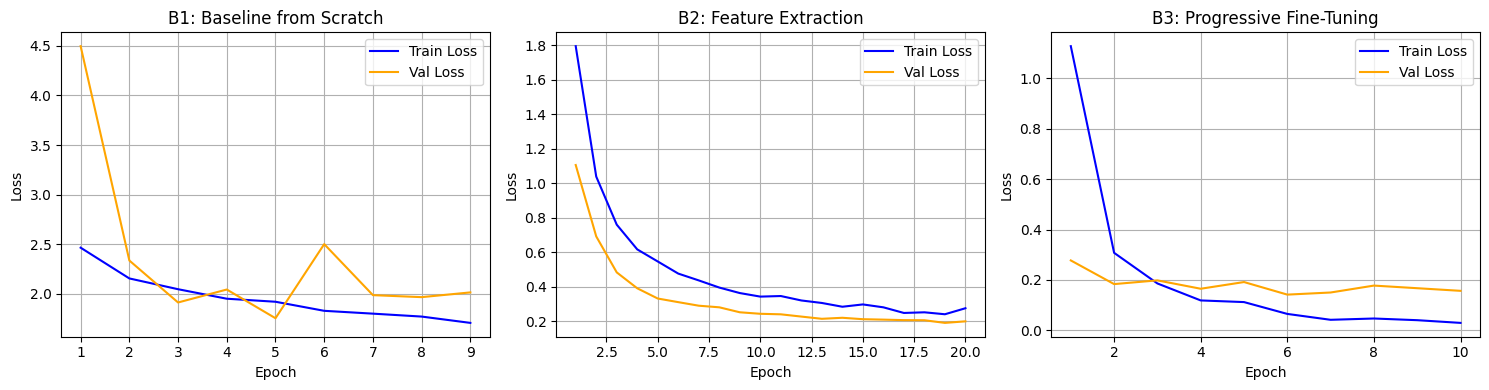

Grafik kurva loss berhasil disimpan sebagai 'kurva_loss_b1_b2_b3.png'


In [ ]:
plt.figure(figsize=(15, 4))

# Plot B1 (From Scratch)
plt.subplot(1, 3, 1)
plt.plot(history_b1['epoch'], history_b1['train_loss'], label='Train Loss', color='blue')
plt.plot(history_b1['epoch'], history_b1['val_loss'], label='Val Loss', color='orange')
plt.title('B1: Baseline from Scratch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot B2 (Feature Extraction)
plt.subplot(1, 3, 2)
plt.plot(history_b2['epoch'], history_b2['train_loss'], label='Train Loss', color='blue')
plt.plot(history_b2['epoch'], history_b2['val_loss'], label='Val Loss', color='orange')
plt.title('B2: Feature Extraction')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot B3 (Fine-Tuning)
plt.subplot(1, 3, 3)
plt.plot(history_b3['epoch'], history_b3['train_loss'], label='Train Loss', color='blue')
plt.plot(history_b3['epoch'], history_b3['val_loss'], label='Val Loss', color='orange')
plt.title('B3: Progressive Fine-Tuning')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('kurva_loss_b1_b2_b3.png', dpi=300)
plt.show()
print("Grafik kurva loss berhasil disimpan sebagai 'kurva_loss_b1_b2_b3.png'")

Daftar Kelas: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


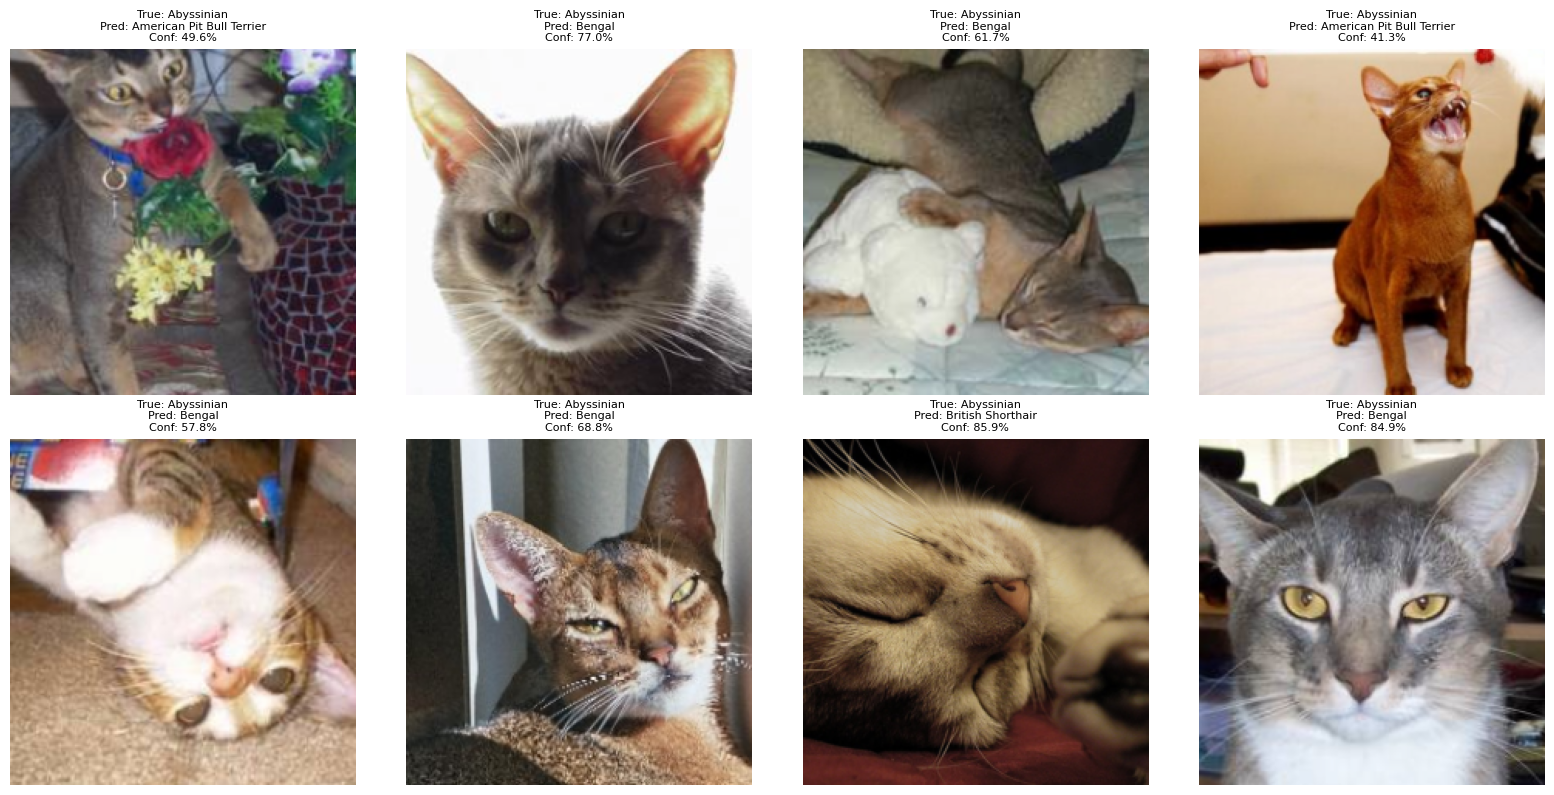

Gambar failure analysis dengan nama ras berhasil diperbarui dan disimpan!


In [ ]:
# 1. Ambil daftar nama kelas (ras hewan) asli dari dataset Oxford-IIIT Pet
class_names = full_dataset_train.classes[:10]
print("Daftar Kelas:", class_names)

# 2. Visualisasikan Failure Analysis dengan Nama Asli
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for idx, sample in enumerate(failure_samples):
    ax = axes[idx // 4, idx % 4]

    # Denormalisasi citra ke bentuk asli untuk ditampilkan
    img = sample["image"].numpy().transpose((1, 2, 0))
    mean = np.array(weights_ref.transforms().mean)
    std = np.array(weights_ref.transforms().std)
    img = std * img + mean
    img = np.clip(img, 0, 1)

    # Ambil nama ras berdasarkan indeks aslinya
    true_name = class_names[sample['true_label']]
    pred_name = class_names[sample['pred_label']]

    ax.imshow(img)
    ax.axis('off')
    # Tampilkan nama ras asli alih-alih angka indeksnya
    ax.set_title(f"True: {true_name}\nPred: {pred_name}\nConf: {sample['confidence']*100:.1f}%", fontsize=8)

plt.tight_layout()
plt.savefig('failure_analysis_samples_named.png', dpi=300)
plt.show()
print("Gambar failure analysis dengan nama ras berhasil diperbarui dan disimpan!")